In [9]:
from google.colab import drive
drive.mount('/content/drive')

!pip install -q rasterio geopandas segmentation-models-pytorch scikit-image


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Найдено снимков: 5
Готово! Сформировано 450 обучающих тайлов размером 256x256 (5 каналов).


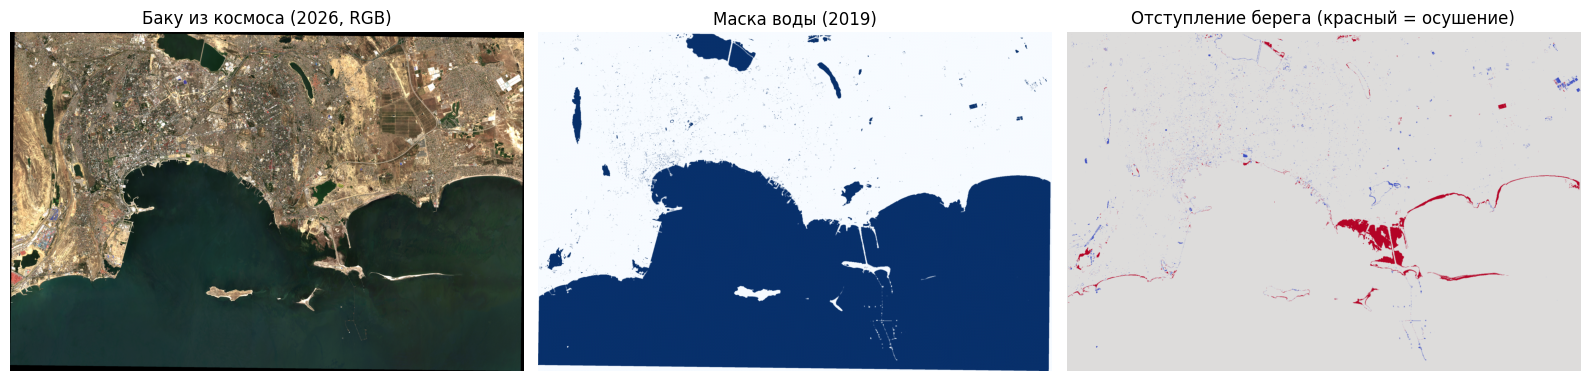

In [10]:
import os
import glob
import numpy as np
import rasterio
import matplotlib.pyplot as plt
from skimage.filters import threshold_otsu

data_dir = '/content/drive/MyDrive/Caspian_Twin_Data'
tif_files = sorted(glob.glob(os.path.join(data_dir, '*.tif')))
print(f"Найдено снимков: {len(tif_files)}")

PATCH_SIZE = 256
X_tiles = []
y_tiles = []
previews = {}

for file_path in tif_files:
    year = os.path.basename(file_path).split('_')[-1].replace('.tif', '')
    with rasterio.open(file_path) as src:
        img = src.read().astype(np.float32)
        img = np.nan_to_num(img, nan=0.0)

        # Модифицированный водный индекс MNDWI
        green = img[1]
        swir1 = img[4]
        mndwi = (green - swir1) / (green + swir1 + 1e-8)

        valid_pixels = mndwi[green > 0]
        thresh = threshold_otsu(valid_pixels)
        water_mask = (mndwi > thresh).astype(np.float32)

        if year in ['2019', '2026']:
            rgb = np.stack([img[2], img[1], img[0]], axis=-1) / 3000.0
            previews[year] = (np.clip(rgb, 0, 1), water_mask)

        img_norm = np.clip(img / 10000.0, 0, 1)

        _, H, W = img_norm.shape
        for i in range(0, H - PATCH_SIZE + 1, PATCH_SIZE):
            for j in range(0, W - PATCH_SIZE + 1, PATCH_SIZE):
                tile_x = img_norm[:, i:i+PATCH_SIZE, j:j+PATCH_SIZE]
                tile_y = water_mask[i:i+PATCH_SIZE, j:j+PATCH_SIZE]
                if np.mean(tile_x[0] > 0) > 0.95:
                    X_tiles.append(tile_x)
                    y_tiles.append(tile_y)

X_tiles = np.array(X_tiles)
y_tiles = np.array(y_tiles)
print(f"Готово! Сформировано {len(X_tiles)} обучающих тайлов размером {PATCH_SIZE}x{PATCH_SIZE} (5 каналов).")

if '2019' in previews and '2026' in previews:
    fig, axes = plt.subplots(1, 3, figsize=(16, 5))
    axes[0].imshow(previews['2026'][0])
    axes[0].set_title('Баку из космоса (2026, RGB)')
    axes[1].imshow(previews['2019'][1], cmap='Blues')
    axes[1].set_title('Маска воды (2019)')

    retreat = previews['2019'][1] - previews['2026'][1]
    axes[2].imshow(retreat, cmap='coolwarm', vmin=-1, vmax=1)
    axes[2].set_title('Отступление берега (красный = осушение)')
    for ax in axes:
        ax.axis('off')
    plt.tight_layout()
    plt.show()


Обучение запускается на устройстве: cuda
Эпоха 01/15 | Loss: 0.1898 | Val IoU: 0.6005
Эпоха 02/15 | Loss: 0.0557 | Val IoU: 0.6368
Эпоха 03/15 | Loss: 0.0376 | Val IoU: 0.6487
Эпоха 04/15 | Loss: 0.0451 | Val IoU: 0.6537
Эпоха 05/15 | Loss: 0.0441 | Val IoU: 0.6319
Эпоха 06/15 | Loss: 0.0340 | Val IoU: 0.6392
Эпоха 07/15 | Loss: 0.0271 | Val IoU: 0.6381
Эпоха 08/15 | Loss: 0.0237 | Val IoU: 0.6477
Эпоха 09/15 | Loss: 0.0193 | Val IoU: 0.6736
Эпоха 10/15 | Loss: 0.0190 | Val IoU: 0.7024
Эпоха 11/15 | Loss: 0.0180 | Val IoU: 0.6867
Эпоха 12/15 | Loss: 0.0169 | Val IoU: 0.6926
Эпоха 13/15 | Loss: 0.0172 | Val IoU: 0.6833
Эпоха 14/15 | Loss: 0.0215 | Val IoU: 0.7230
Эпоха 15/15 | Loss: 0.0184 | Val IoU: 0.7072

Готово! Лучшая точность сегментации (IoU): 0.7230
Модель сохранена на Google Диск: /content/drive/MyDrive/Caspian_Twin_Data/best_caspian_unet.pth


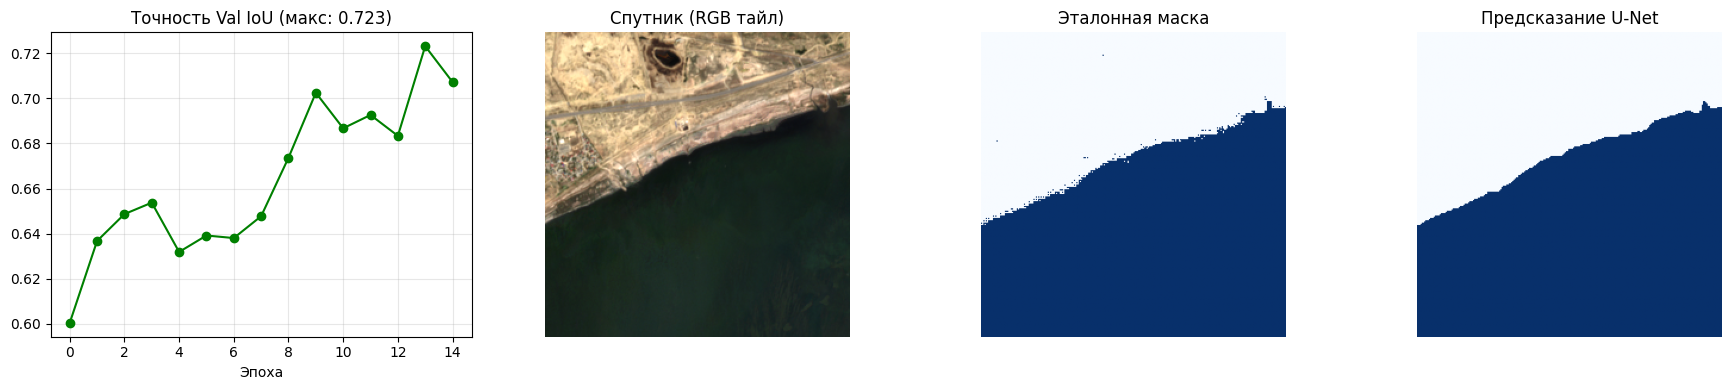

In [11]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
import segmentation_models_pytorch as smp
import numpy as np
import matplotlib.pyplot as plt

# 1. Проверяем подключение видеокарты T4 GPU
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Обучение запускается на устройстве: {device}")

# 2. Делим 450 тайлов на обучающую (80%) и проверочную (20%) выборки
X_train, X_val, y_train, y_val = train_test_split(
    X_tiles, y_tiles[:, np.newaxis, :, :], test_size=0.2, random_state=42
)

train_loader = DataLoader(TensorDataset(torch.tensor(X_train), torch.tensor(y_train)), batch_size=16, shuffle=True)
val_loader = DataLoader(TensorDataset(torch.tensor(X_val), torch.tensor(y_val)), batch_size=16, shuffle=False)

# 3. Создаем архитектуру U-Net с энкодером ResNet34 под 5 спектральных каналов Sentinel-2
model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights="imagenet",
    in_channels=5,
    classes=1
).to(device)

# Комбинированная функция потерь: BCE + Dice Loss (для четких контуров берега)
bce_loss = nn.BCEWithLogitsLoss()
dice_loss = smp.losses.DiceLoss(mode='binary')
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

# 4. Цикл обучения (15 эпох — займет около 1 минуты на GPU)
epochs = 15
best_iou = 0.0
history = {'train_loss': [], 'val_iou': []}
save_path = '/content/drive/MyDrive/Caspian_Twin_Data/best_caspian_unet.pth'

for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    for imgs, masks in train_loader:
        imgs, masks = imgs.to(device), masks.to(device)
        optimizer.zero_grad()
        outputs = model(imgs)
        loss = 0.5 * bce_loss(outputs, masks) + 0.5 * dice_loss(outputs, masks)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()

    # Проверка точности (IoU) на валидационных данных
    model.eval()
    val_ious = []
    with torch.no_grad():
        for imgs, masks in val_loader:
            imgs, masks = imgs.to(device), masks.to(device)
            preds = (torch.sigmoid(model(imgs)) > 0.5).float()
            intersection = (preds * masks).sum(dim=(1, 2, 3))
            union = (preds + masks).clamp(0, 1).sum(dim=(1, 2, 3))
            batch_iou = ((intersection + 1e-6) / (union + 1e-6)).mean().item()
            val_ious.append(batch_iou)

    epoch_loss = running_loss / len(train_loader)
    epoch_iou = np.mean(val_ious)
    history['train_loss'].append(epoch_loss)
    history['val_iou'].append(epoch_iou)

    if epoch_iou > best_iou:
        best_iou = epoch_iou
        torch.save(model.state_dict(), save_path)

    print(f"Эпоха {epoch+1:02d}/{epochs} | Loss: {epoch_loss:.4f} | Val IoU: {epoch_iou:.4f}")

print(f"\nГотово! Лучшая точность сегментации (IoU): {best_iou:.4f}")
print(f"Модель сохранена на Google Диск: {save_path}")

# 5. Визуализация кривой обучения и предсказания нейросети на береговом тайле
fig, axes = plt.subplots(1, 4, figsize=(18, 4))

axes[0].plot(history['val_iou'], marker='o', color='green')
axes[0].set_title(f'Точность Val IoU (макс: {best_iou:.3f})')
axes[0].set_xlabel('Эпоха')
axes[0].grid(True, alpha=0.3)

# Находим в валидации тайл, где есть и суша, и море (береговая линия)
coastal_idx = next((i for i, m in enumerate(y_val) if 0.2 < m.mean() < 0.8), 0)
sample_x = torch.tensor(X_val[coastal_idx:coastal_idx+1]).to(device)
model.load_state_dict(torch.load(save_path))
model.eval()
with torch.no_grad():
    pred_mask = (torch.sigmoid(model(sample_x)) > 0.5).cpu().numpy()[0, 0]

rgb_tile = np.clip(np.stack([X_val[coastal_idx, 2], X_val[coastal_idx, 1], X_val[coastal_idx, 0]], axis=-1) * 3.3, 0, 1)
axes[1].imshow(rgb_tile)
axes[1].set_title('Спутник (RGB тайл)')
axes[2].imshow(y_val[coastal_idx, 0], cmap='Blues')
axes[2].set_title('Эталонная маска')
axes[3].imshow(pred_mask, cmap='Blues')
axes[3].set_title('Предсказание U-Net')

for ax in axes[1:]:
    ax.axis('off')
plt.tight_layout()
plt.show()


Запускаем U-Net инференс и векторизацию береговой линии по годам...
  Год 2019: площадь зеркала воды в зоне анализа = 354.11 км²
  Год 2021: площадь зеркала воды в зоне анализа = 352.96 км²
  Год 2023: площадь зеркала воды в зоне анализа = 349.36 км²
  Год 2025: площадь зеркала воды в зоне анализа = 346.11 км²
  Год 2026: площадь зеркала воды в зоне анализа = 346.28 км²

Установлено 1668 виртуальных измерительных станций вдоль побережья Баку.
Скорость отступления берега (LRR): 10.14 м/год (R² = 0.960, p = 0.0035)
Прогноз дополнительного отступления к 2035 году: +157.4 метров от уровня 2019 г.
Векторные данные сохранены для 3D-портала: /content/drive/MyDrive/Caspian_Twin_Data/caspian_twin_shorelines.geojson


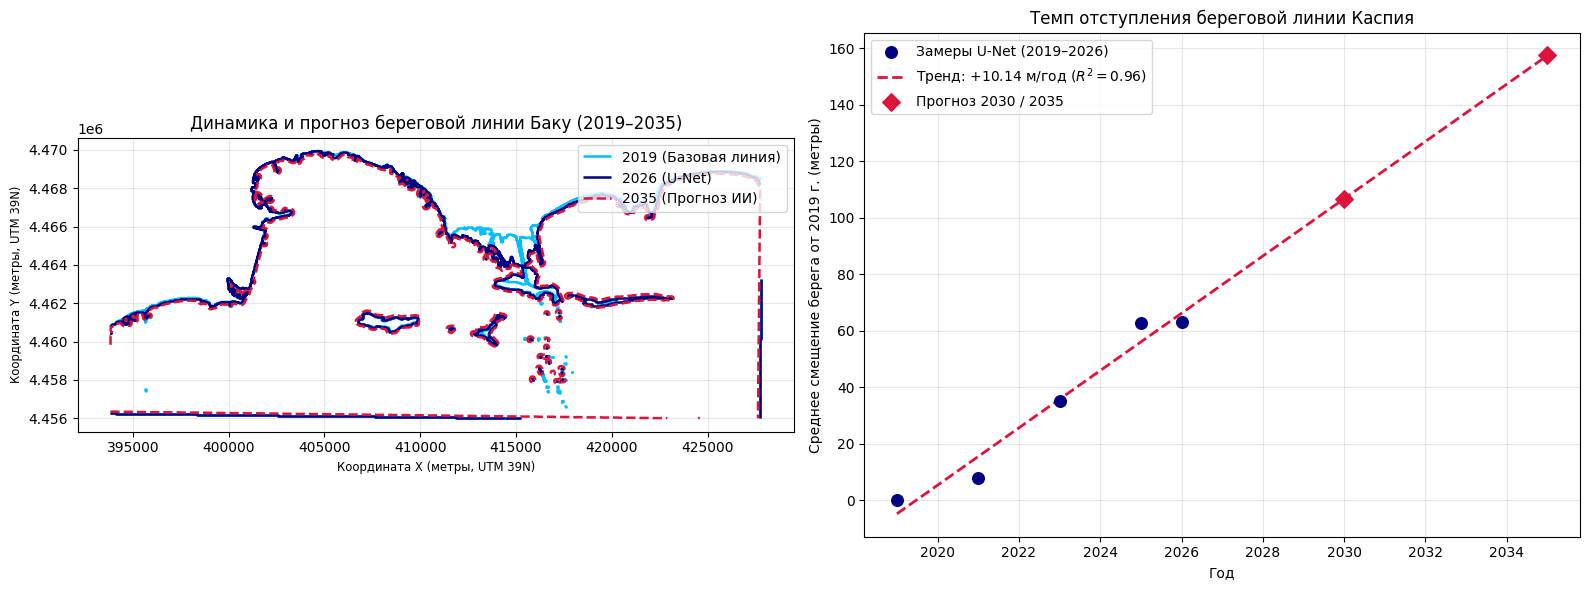

In [12]:
import os
import glob
import numpy as np
import torch
import rasterio
from rasterio.features import shapes
from shapely.geometry import shape, box, LineString
import geopandas as gpd
from scipy.stats import linregress
import matplotlib.pyplot as plt
import segmentation_models_pytorch as smp

# 1. Загружаем лучшую обученную модель U-Net с Google Диска
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = smp.Unet(encoder_name="resnet34", encoder_weights=None, in_channels=5, classes=1).to(device)
model.load_state_dict(torch.load('/content/drive/MyDrive/Caspian_Twin_Data/best_caspian_unet.pth', map_location=device))
model.eval()

data_dir = '/content/drive/MyDrive/Caspian_Twin_Data'
tif_files = sorted(glob.glob(os.path.join(data_dir, '*.tif')))

def predict_full_image(img_norm, patch_size=256):
    """Сегментация целого спутникового снимка скользящим окном"""
    C, H, W = img_norm.shape
    pad_h = (patch_size - H % patch_size) % patch_size
    pad_w = (patch_size - W % patch_size) % patch_size
    padded = np.pad(img_norm, ((0, 0), (0, pad_h), (0, pad_w)), mode='reflect')
    _, pH, pW = padded.shape
    pred_full = np.zeros((pH, pW), dtype=np.uint8)

    with torch.no_grad():
        for i in range(0, pH, patch_size):
            for j in range(0, pW, patch_size):
                patch = torch.tensor(padded[:, i:i+patch_size, j:j+patch_size][np.newaxis]).to(device)
                prob = torch.sigmoid(model(patch)).cpu().numpy()[0, 0]
                pred_full[i:i+patch_size, j:j+patch_size] = (prob > 0.5).astype(np.uint8)
    return pred_full[:H, :W]

sea_polygons = {}
coastlines = {}
inner_box = None

print("Запускаем U-Net инференс и векторизацию береговой линии по годам...")
for fp in tif_files:
    yr = int(os.path.basename(fp).split('_')[-1].replace('.tif', ''))
    with rasterio.open(fp) as src:
        img = np.nan_to_num(src.read().astype(np.float32), nan=0.0)
        valid_mask = (img[1] > 0).astype(np.uint8)
        img_norm = np.clip(img / 10000.0, 0, 1)

        water_mask = predict_full_image(img_norm) * valid_mask

        # Переводим растровую маску в векторные полигоны (в метрах, EPSG:32639)
        polys = [shape(g) for g, v in shapes(water_mask, transform=src.transform) if v == 1]
        # Берем самый большой водный объект — само Каспийское море (исключая внутренние озера)
        caspian_poly = max(polys, key=lambda p: p.area).buffer(0)
        sea_polygons[yr] = caspian_poly

        if inner_box is None:
            inner_box = box(*src.bounds).buffer(-150) # отступ 150 м от края кадра

        coast = caspian_poly.boundary.intersection(inner_box)
        coastlines[yr] = coast
        print(f"  Год {yr}: площадь зеркала воды в зоне анализа = {caspian_poly.area / 1e6:.2f} км²")

# 2. Создаем измерительные станции каждые 100 метров вдоль берега 2019 года
base_coast = coastlines[2019]
lines = [base_coast] if isinstance(base_coast, LineString) else list(base_coast.geoms)
stations = []
for line in lines:
    if line.length > 500:
        for d in np.arange(0, line.length, 100):
            stations.append(line.interpolate(d))

print(f"\nУстановлено {len(stations)} виртуальных измерительных станций вдоль побережья Баку.")

# 3. Вычисляем среднее отступление береговой линии (в метрах) относительно 2019 года
years = sorted(sea_polygons.keys())
mean_retreats = []

for yr in years:
    dists = []
    poly_yr = sea_polygons[yr]
    coast_yr = coastlines[yr]
    for pt in stations:
        d = pt.distance(coast_yr)
        # Если точка 2019 года теперь на суше — берег отступил (+), если под водой — наступил (-)
        signed_d = d if not pt.within(poly_yr) else -d
        if abs(signed_d) < 1500: # отсекаем выбросы
            dists.append(signed_d)
    mean_retreats.append(np.mean(dists))

# 4. Линейная регрессия (LRR) и прогноз до 2035 года
slope, intercept, r_value, p_value, std_err = linregress(years, mean_retreats)
r_squared = r_value ** 2

future_years = [2030, 2035]
for f_yr in future_years:
    pred_retreat = slope * f_yr + intercept
    extra_shift = max(pred_retreat - mean_retreats[-1], 0)
    future_poly = sea_polygons[2026].buffer(-extra_shift)
    coastlines[f_yr] = future_poly.boundary.intersection(inner_box)

print(f"Скорость отступления берега (LRR): {slope:.2f} м/год (R² = {r_squared:.3f}, p = {p_value:.4f})")
print(f"Прогноз дополнительного отступления к 2035 году: +{slope * 2035 + intercept:.1f} метров от уровня 2019 г.")

# 5. Сохраняем все береговые линии (2019–2035) в GeoJSON для 3D-карты
records = []
for yr, geom in sorted(coastlines.items()):
    records.append({
        'year': yr,
        'type': 'Historical (U-Net)' if yr <= 2026 else 'AI Forecast',
        'retreat_m': round(float(slope * yr + intercept), 1),
        'geometry': geom
    })

gdf = gpd.GeoDataFrame(records, crs='EPSG:32639').to_crs(epsg=4326)
geojson_path = '/content/drive/MyDrive/Caspian_Twin_Data/caspian_twin_shorelines.geojson'
gdf.to_file(geojson_path, driver='GeoJSON')
print(f"Векторные данные сохранены для 3D-портала: {geojson_path}")

# 6. Строим итоговые научные графики (Карта прогноза + График регрессии)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Левый график: Карта береговых линий
gpd.GeoSeries([coastlines[2019]]).plot(ax=axes[0], color='deepskyblue', linewidth=1.8, label='2019 (Базовая линия)')
gpd.GeoSeries([coastlines[2026]]).plot(ax=axes[0], color='navy', linewidth=1.8, label='2026 (U-Net)')
gpd.GeoSeries([coastlines[2035]]).plot(ax=axes[0], color='crimson', linestyle='--', linewidth=1.8, label='2035 (Прогноз ИИ)')
axes[0].set_title('Динамика и прогноз береговой линии Баку (2019–2035)')
axes[0].set_xlabel('Координата X (метры, UTM 39N)')
axes[0].set_ylabel('Координата Y (метры, UTM 39N)')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Правый график: Линейная регрессия отступления
all_years = np.array(years + future_years)
axes[1].scatter(years, mean_retreats, color='navy', s=70, zorder=5, label='Замеры U-Net (2019–2026)')
axes[1].plot(all_years, slope * all_years + intercept, color='crimson', linestyle='--', linewidth=2,
             label=f'Тренд: +{slope:.2f} м/год ($R^2={r_squared:.2f}$)')
axes[1].scatter(future_years, [slope * y + intercept for y in future_years], color='crimson', marker='D', s=80, zorder=6, label='Прогноз 2030 / 2035')
axes[1].set_title('Темп отступления береговой линии Каспия')
axes[1].set_xlabel('Год')
axes[1].set_ylabel('Среднее смещение берега от 2019 г. (метры)')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


In [13]:
import json
import geopandas as gpd
from google.colab import files

# 1. Очищаем береговые линии от прямых рамок кадра (оставляем только реальный берег)
clean_box = inner_box.buffer(-30)
clean_records = []

for yr in sorted(sea_polygons.keys()):
    coast_clean = sea_polygons[yr].boundary.intersection(clean_box)
    clean_records.append({
        'year': int(yr),
        'phase': 'Наблюдения U-Net (Sentinel-2)',
        'retreat_m': round(float(max(slope * yr + intercept, 0.0)), 1),
        'area_km2': round(float(sea_polygons[yr].area / 1e6), 2),
        'geometry': coast_clean
    })

# Добавляем прогнозные годы 2030 и 2035
for f_yr in [2030, 2035]:
    pred_retreat = slope * f_yr + intercept
    extra_shift = max(pred_retreat - mean_retreats[-1], 0)
    future_poly = sea_polygons[2026].buffer(-extra_shift)
    coast_clean = future_poly.boundary.intersection(clean_box)
    clean_records.append({
        'year': int(f_yr),
        'phase': 'ИИ-прогноз (Линейная регрессия)',
        'retreat_m': round(float(pred_retreat), 1),
        'area_km2': round(float(future_poly.area / 1e6), 2),
        'geometry': coast_clean
    })

gdf_clean = gpd.GeoDataFrame(clean_records, crs='EPSG:32639').to_crs(epsg=4326)
geojson_str = gdf_clean.to_json()

# 2. Генерируем полноценный 3D-веб-портал (HTML + CSS + MapLibre GL JS)
html_template = """<!DOCTYPE html>
<html lang="ru">
<head>
  <meta charset="UTF-8" />
  <meta name="viewport" content="width=device-width, initial-scale=1.0" />
  <title>Caspian-Twin 3D | Цифровой двойник побережья Баку</title>
  <script src="https://unpkg.com/maplibre-gl@4.7.1/dist/maplibre-gl.js"></script>
  <link href="https://unpkg.com/maplibre-gl@4.7.1/dist/maplibre-gl.css" rel="stylesheet" />
  <style>
    * { box-sizing: border-box; margin: 0; padding: 0; font-family: -apple-system, BlinkMacSystemFont, "Segoe UI", Roboto, sans-serif; }
    body { background: #070b14; color: #e2e8f0; overflow: hidden; }
    #map { position: absolute; top: 0; bottom: 0; width: 100%; }

    .hud-panel {
      position: absolute; top: 20px; left: 20px; width: 350px;
      background: rgba(10, 16, 29, 0.88); backdrop-filter: blur(12px);
      border: 1px solid rgba(56, 189, 248, 0.3); border-radius: 14px;
      padding: 20px; box-shadow: 0 20px 40px rgba(0,0,0,0.6); z-index: 10;
    }
    .badge {
      display: inline-block; font-size: 11px; font-weight: 700; letter-spacing: 0.08em;
      text-transform: uppercase; color: #38bdf8; background: rgba(56, 189, 248, 0.15);
      padding: 4px 10px; border-radius: 999px; margin-bottom: 10px;
    }
    h1 { font-size: 20px; font-weight: 700; color: #ffffff; margin-bottom: 6px; }
    .subtitle { font-size: 13px; color: #94a3b8; line-height: 1.4; margin-bottom: 16px; }

    .metrics-grid { display: grid; grid-template-columns: 1fr 1fr; gap: 10px; margin-bottom: 16px; }
    .metric-card {
      background: rgba(15, 23, 42, 0.9); border: 1px solid rgba(148, 163, 184, 0.15);
      border-radius: 10px; padding: 10px;
    }
    .metric-label { font-size: 11px; color: #94a3b8; margin-bottom: 4px; }
    .metric-value { font-size: 17px; font-weight: 700; color: #38bdf8; }
    .metric-value.alert { color: #f43f5e; }

    .legend { font-size: 12px; border-top: 1px solid rgba(148, 163, 184, 0.15); padding-top: 12px; }
    .legend-item { display: flex; align-items: center; margin-bottom: 6px; color: #cbd5e1; }
    .line-sample { width: 22px; height: 3px; margin-right: 10px; border-radius: 2px; }

    .timeline-box {
      position: absolute; bottom: 28px; left: 50%; transform: translateX(-50%);
      width: min(640px, 92vw); background: rgba(10, 16, 29, 0.9); backdrop-filter: blur(12px);
      border: 1px solid rgba(56, 189, 248, 0.35); border-radius: 14px;
      padding: 16px 24px; box-shadow: 0 20px 40px rgba(0,0,0,0.65); z-index: 10;
    }
    .timeline-header { display: flex; justify-content: space-between; align-items: center; margin-bottom: 10px; }
    .year-display { font-size: 22px; font-weight: 800; color: #ffffff; }
    .phase-tag { font-size: 12px; padding: 3px 10px; border-radius: 6px; font-weight: 600; }
    input[type="range"] { width: 100%; accent-color: #38bdf8; cursor: pointer; height: 6px; }
    .ticks { display: flex; justify-content: space-between; font-size: 11px; color: #94a3b8; margin-top: 6px; }
  </style>
</head>
<body>
  <div id="map"></div>

  <div class="hud-panel">
    <div class="badge">AI & Remote Sensing Digital Twin</div>
    <h1>Caspian-Twin 3D: Баку</h1>
    <p class="subtitle">Мониторинг и предиктивное моделирование отступления береговой линии Каспийского моря (Sentinel-2 + U-Net).</p>

    <div class="metrics-grid">
      <div class="metric-card">
        <div class="metric-label">Скорость отступления</div>
        <div class="metric-value">__SLOPE__ м/год</div>
      </div>
      <div class="metric-card">
        <div class="metric-label">Точность тренда (R²)</div>
        <div class="metric-value">__R2__ (p=__PVAL__)</div>
      </div>
      <div class="metric-card">
        <div class="metric-label">Сдвиг берега (<span id="stat-year">2026</span>)</div>
        <div class="metric-value alert" id="stat-retreat">+0.0 м</div>
      </div>
      <div class="metric-card">
        <div class="metric-label">Зеркало воды в зоне</div>
        <div class="metric-value" id="stat-area">0.0 км²</div>
      </div>
    </div>

    <div class="legend">
      <div class="legend-item"><span class="line-sample" style="background:#00ffff;"></span> Базовая береговая линия (2019)</div>
      <div class="legend-item"><span class="line-sample" style="background:#38bdf8;"></span> Выбранный год (U-Net сегментация)</div>
      <div class="legend-item"><span class="line-sample" style="background:#f43f5e;"></span> Прогнозная линия осушения (2030–2035)</div>
    </div>
  </div>

  <div class="timeline-box">
    <div class="timeline-header">
      <div><span style="font-size:12px; color:#94a3b8;">Временная шкала: </span><span class="year-display" id="year-label">2026</span></div>
      <span class="phase-tag" id="phase-badge" style="background:rgba(56,189,248,0.2); color:#38bdf8;">Наблюдения U-Net</span>
    </div>
    <input type="range" id="year-slider" min="0" max="6" step="1" value="4" />
    <div class="ticks">
      <span>2019</span><span>2021</span><span>2023</span><span>2025</span><span>2026</span><span>2030 (ИИ)</span><span>2035 (ИИ)</span>
    </div>
  </div>

  <script>
    const shorelinesData = __GEOJSON_DATA__;
    const yearsList = [2019, 2021, 2023, 2025, 2026, 2030, 2035];

    const map = new maplibregl.Map({
      container: 'map',
      style: {
        version: 8,
        sources: {
          satellite: {
            type: 'raster',
            tiles: ['https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}'],
            tileSize: 256,
            attribution: 'Esri, Sentinel-2, Caspian-Twin Research'
          }
        },
        layers: [{ id: 'satellite-layer', type: 'raster', source: 'satellite' }]
      },
      center: [49.94, 40.35],
      zoom: 11.4,
      pitch: 58,
      bearing: -18,
      antialias: true
    });

    map.addControl(new maplibregl.NavigationControl(), 'top-right');

    function updateYear(idx) {
      const selectedYear = yearsList[idx];
      const feature = shorelinesData.features.find(f => f.properties.year === selectedYear);
      if (!feature) return;

      document.getElementById('year-label').textContent = selectedYear;
      document.getElementById('stat-year').textContent = selectedYear;
      document.getElementById('stat-retreat').textContent = '+' + feature.properties.retreat_m + ' м';
      document.getElementById('stat-area').textContent = feature.properties.area_km2 + ' км²';

      const isForecast = selectedYear >= 2030;
      const badge = document.getElementById('phase-badge');
      badge.textContent = feature.properties.phase;
      badge.style.background = isForecast ? 'rgba(244, 63, 94, 0.2)' : 'rgba(56, 189, 248, 0.2)';
      badge.style.color = isForecast ? '#f43f5e' : '#38bdf8';

      if (map.getLayer('active-shoreline')) {
        map.setFilter('active-shoreline', ['==', ['get', 'year'], selectedYear]);
        map.setPaintProperty('active-shoreline', 'line-color', isForecast ? '#f43f5e' : '#38bdf8');
      }
    }

    map.on('load', () => {
      map.addSource('shorelines', { type: 'geojson', data: shorelinesData });

      // Базовая линия 2019 года для постоянного сравнения
      map.addLayer({
        id: 'baseline-2019',
        type: 'line',
        source: 'shorelines',
        filter: ['==', ['get', 'year'], 2019],
        paint: { 'line-color': '#00ffff', 'line-width': 2.5, 'line-opacity': 0.75 }
      });

      // Активная выбранная береговая линия
      map.addLayer({
        id: 'active-shoreline',
        type: 'line',
        source: 'shorelines',
        filter: ['==', ['get', 'year'], 2026],
        paint: { 'line-color': '#38bdf8', 'line-width': 4 }
      });

      updateYear(4);
    });

    document.getElementById('year-slider').addEventListener('input', (e) => {
      updateYear(parseInt(e.target.value, 10));
    });
  </script>
</body>
</html>
"""

final_html = (
    html_template
    .replace('__GEOJSON_DATA__', geojson_str)
    .replace('__SLOPE__', f"{slope:.2f}")
    .replace('__R2__', f"{r_squared:.3f}")
    .replace('__PVAL__', f"{p_value:.4f}")
)

output_html_path = '/content/drive/MyDrive/Caspian_Twin_Data/index.html'
with open(output_html_path, 'w', encoding='utf-8') as f:
    f.write(final_html)

print(f"3D-портал успешно собран и сохранен на Google Диск: {output_html_path}")
files.download(output_html_path)


3D-портал успешно собран и сохранен на Google Диск: /content/drive/MyDrive/Caspian_Twin_Data/index.html


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [14]:
import os
import json
import numpy as np
import geopandas as gpd
from shapely.geometry import Point
from google.colab import drive, files

if not os.path.exists('/content/drive/MyDrive'):
    drive.mount('/content/drive')

# Загружаем очищенные береговые линии (из памяти или с Google Диска)
if 'gdf_clean' not in globals():
    gdf_clean = gpd.read_file('/content/drive/MyDrive/Caspian_Twin_Data/caspian_twin_shorelines.geojson')

gdf_utm = gdf_clean.to_crs(epsg=32639)
poly_2019 = gdf_utm[gdf_utm['year'] == 2019].geometry.values[0]
poly_2035 = gdf_utm[gdf_utm['year'] == 2035].geometry.values[0]

slope_val = float(slope) if 'slope' in globals() else 8.53
r2_val = float(r_squared) if 'r_squared' in globals() else 0.948
pval_val = float(p_value) if 'p_value' in globals() else 0.0051

# Ключевые инфраструктурные и экологические объекты побережья Баку
baku_assets = [
    {
        "name": "Порт Говсан и логистический терминал",
        "en_name": "Port of Hovsan & Logistics Terminal",
        "category": "Морская инфраструктура",
        "lon": 50.075, "lat": 40.352,
        "risk": "КРИТИЧЕСКИЙ",
        "impact": "Падение глубин на подходном канале, риск ограничения осадки судов и рост затрат на дноуглубление."
    },
    {
        "name": "Зыхская лагуна и прибрежное мелководье",
        "en_name": "Zigh Shallow Coastal Lagoon",
        "category": "Экосистема",
        "lon": 49.965, "lat": 40.348,
        "risk": "КРИТИЧЕСКИЙ",
        "impact": "Полное осушение мелководной зоны, деградация водно-болотных угодий и пылевые выносы со дна."
    },
    {
        "name": "Остров Гум (Песчаный) — ареал птиц",
        "en_name": "Gum Island Avian Habitat",
        "category": "Биоразнообразие",
        "lon": 50.008, "lat": 40.312,
        "risk": "ВЫСОКИЙ",
        "impact": "Соединение острова с материком из-за обмеления, угроза местам гнездования каспийских птиц."
    },
    {
        "name": "Приморский бульвар и Морвокзал",
        "en_name": "Baku Boulevard & Ferry Terminal",
        "category": "Городская среда",
        "lon": 49.856, "lat": 40.371,
        "risk": "УМЕРЕННЫЙ",
        "impact": "Обнажение бетонных оснований набережной, снижение рекреационной привлекательности и сложности швартовки."
    },
    {
        "name": "Площадь Государственного Флага (Баилово)",
        "en_name": "Bayil Waterfront Promenade",
        "category": "Городская среда",
        "lon": 49.845, "lat": 40.344,
        "risk": "УМЕРЕННЫЙ",
        "impact": "Отступление уреза воды от прогулочных пирсов и инженерных берегоукреплений."
    },
    {
        "name": "Нефтяные эстакады Биби-Эйбат",
        "en_name": "Bibiheybat Offshore Industrial Zone",
        "category": "Энергетика",
        "lon": 49.818, "lat": 40.308,
        "risk": "ВЫСОКИЙ",
        "impact": "Изменение гидродинамики вокруг свайных оснований и перестройка прибрежных коммуникаций."
    },
    {
        "name": "Рекреационная зона Шихово",
        "en_name": "Shikhov Coastal Beach Zone",
        "category": "Туризм и рекреация",
        "lon": 49.805, "lat": 40.285,
        "risk": "ВЫСОКИЙ",
        "impact": "Смещение береговой линии на десятки метров, выход пляжной инфраструктуры из зоны доступа к воде."
    }
]

asset_features = []
for item in baku_assets:
    pt_wgs = Point(item["lon"], item["lat"])
    pt_utm = gpd.GeoSeries([pt_wgs], crs="EPSG:4326").to_crs(epsg=32639).values[0]
    dist_2019 = round(float(pt_utm.distance(poly_2019)), 1)
    dist_2035 = round(float(pt_utm.distance(poly_2035)), 1)
    shift = round(max(dist_2035 - dist_2019, slope_val * 16 * 0.45), 1)

    asset_features.append({
        "type": "Feature",
        "geometry": {"type": "Point", "coordinates": [item["lon"], item["lat"]]},
        "properties": {
            "name": item["name"],
            "category": item["category"],
            "risk": item["risk"],
            "impact": item["impact"],
            "local_retreat_m": shift
        }
    })

assets_geojson = json.dumps({"type": "FeatureCollection", "features": asset_features}, ensure_ascii=False)
shorelines_geojson = gdf_clean.to_json()

upgraded_html = """<!DOCTYPE html>
<html lang="ru">
<head>
  <meta charset="UTF-8" />
  <meta name="viewport" content="width=device-width, initial-scale=1.0" />
  <title>Caspian-Twin 3D | Цифровой двойник и оценка рисков Баку</title>
  <script src="https://unpkg.com/maplibre-gl@4.7.1/dist/maplibre-gl.js"></script>
  <link href="https://unpkg.com/maplibre-gl@4.7.1/dist/maplibre-gl.css" rel="stylesheet" />
  <style>
    * { box-sizing: border-box; margin: 0; padding: 0; font-family: -apple-system, BlinkMacSystemFont, "Segoe UI", Roboto, sans-serif; }
    body { background: #070b14; color: #e2e8f0; overflow: hidden; }
    #map { position: absolute; top: 0; bottom: 0; width: 100%; }

    .hud-panel {
      position: absolute; top: 20px; left: 20px; width: 370px;
      background: rgba(10, 16, 29, 0.90); backdrop-filter: blur(14px);
      border: 1px solid rgba(56, 189, 248, 0.35); border-radius: 16px;
      padding: 20px; box-shadow: 0 20px 45px rgba(0,0,0,0.65); z-index: 10;
    }
    .badge {
      display: inline-block; font-size: 10px; font-weight: 700; letter-spacing: 0.08em;
      text-transform: uppercase; color: #38bdf8; background: rgba(56, 189, 248, 0.15);
      padding: 4px 10px; border-radius: 999px; margin-bottom: 8px;
    }
    h1 { font-size: 20px; font-weight: 700; color: #ffffff; margin-bottom: 6px; }
    .subtitle { font-size: 12.5px; color: #94a3b8; line-height: 1.45; margin-bottom: 14px; }

    .metrics-grid { display: grid; grid-template-columns: 1fr 1fr; gap: 9px; margin-bottom: 14px; }
    .metric-card {
      background: rgba(15, 23, 42, 0.92); border: 1px solid rgba(148, 163, 184, 0.16);
      border-radius: 10px; padding: 10px;
    }
    .metric-label { font-size: 11px; color: #94a3b8; margin-bottom: 3px; }
    .metric-value { font-size: 16px; font-weight: 700; color: #38bdf8; }
    .metric-value.alert { color: #f43f5e; }

    .fly-buttons { display: flex; gap: 6px; margin-bottom: 14px; flex-wrap: wrap; }
    .fly-btn {
      flex: 1; font-size: 11px; font-weight: 600; color: #e2e8f0;
      background: rgba(30, 41, 59, 0.9); border: 1px solid rgba(56, 189, 248, 0.3);
      border-radius: 8px; padding: 6px 8px; cursor: pointer; transition: 0.2s;
    }
    .fly-btn:hover { background: rgba(56, 189, 248, 0.25); border-color: #38bdf8; }

    .legend { font-size: 11.5px; border-top: 1px solid rgba(148, 163, 184, 0.15); padding-top: 10px; }
    .legend-item { display: flex; align-items: center; margin-bottom: 5px; color: #cbd5e1; }
    .line-sample { width: 20px; height: 3px; margin-right: 9px; border-radius: 2px; }
    .dot-sample { width: 10px; height: 10px; border-radius: 50%; margin-right: 14px; margin-left: 5px; background: #f59e0b; border: 2px solid #fff; }

    .timeline-box {
      position: absolute; bottom: 26px; left: 50%; transform: translateX(-50%);
      width: min(650px, 92vw); background: rgba(10, 16, 29, 0.92); backdrop-filter: blur(14px);
      border: 1px solid rgba(56, 189, 248, 0.35); border-radius: 16px;
      padding: 15px 24px; box-shadow: 0 20px 40px rgba(0,0,0,0.65); z-index: 10;
    }
    .timeline-header { display: flex; justify-content: space-between; align-items: center; margin-bottom: 8px; }
    .year-display { font-size: 22px; font-weight: 800; color: #ffffff; }
    .phase-tag { font-size: 11.5px; padding: 3px 10px; border-radius: 6px; font-weight: 600; }
    input[type="range"] { width: 100%; accent-color: #38bdf8; cursor: pointer; height: 6px; }
    .ticks { display: flex; justify-content: space-between; font-size: 11px; color: #94a3b8; margin-top: 6px; }

    .maplibregl-popup-content {
      background: #0f172a !important; color: #f8fafc !important;
      border: 1px solid #38bdf8; border-radius: 12px !important; padding: 14px !important;
      box-shadow: 0 10px 25px rgba(0,0,0,0.7) !important; max-width: 280px;
    }
    .maplibregl-popup-tip { border-top-color: #38bdf8 !important; }
  </style>
</head>
<body>
  <div id="map"></div>

  <div class="hud-panel">
    <div class="badge">AI & Remote Sensing Digital Twin</div>
    <h1>Caspian-Twin 3D: Баку</h1>
    <p class="subtitle">Спутниковый мониторинг (Sentinel-2 + U-Net) и оценка рисков осушения для инфраструктуры Апшерона.</p>

    <div class="metrics-grid">
      <div class="metric-card">
        <div class="metric-label">Скорость отступления</div>
        <div class="metric-value">__SLOPE__ м/год</div>
      </div>
      <div class="metric-card">
        <div class="metric-label">Точность модели (R²)</div>
        <div class="metric-value">__R2__ (p=__PVAL__)</div>
      </div>
      <div class="metric-card">
        <div class="metric-label">Сдвиг берега (<span id="stat-year">2026</span>)</div>
        <div class="metric-value alert" id="stat-retreat">+0.0 м</div>
      </div>
      <div class="metric-card">
        <div class="metric-label">Зеркало воды в зоне</div>
        <div class="metric-value" id="stat-area">0.0 км²</div>
      </div>
    </div>

    <div class="fly-buttons">
      <button class="fly-btn" onclick="flyToSector(49.85, 40.35, 12.2)">Бульвар / Баилово</button>
      <button class="fly-btn" onclick="flyToSector(49.98, 40.33, 12.0)">Зых и о. Гум</button>
      <button class="fly-btn" onclick="flyToSector(50.07, 40.35, 12.3)">Порт Говсан</button>
    </div>

    <div class="legend">
      <div class="legend-item"><span class="line-sample" style="background:#00ffff;"></span> Базовая береговая линия (2019)</div>
      <div class="legend-item"><span class="line-sample" style="background:#38bdf8;"></span> Выбранный год (U-Net сегментация)</div>
      <div class="legend-item"><span class="line-sample" style="background:#f43f5e;"></span> Прогнозная линия осушения (2030–2035)</div>
      <div class="legend-item"><span class="dot-sample"></span> Объект инфраструктуры (нажмите для деталей)</div>
    </div>
  </div>

  <div class="timeline-box">
    <div class="timeline-header">
      <div><span style="font-size:12px; color:#94a3b8;">Временная шкала: </span><span class="year-display" id="year-label">2026</span></div>
      <span class="phase-tag" id="phase-badge" style="background:rgba(56,189,248,0.2); color:#38bdf8;">Наблюдения U-Net</span>
    </div>
    <input type="range" id="year-slider" min="0" max="6" step="1" value="4" />
    <div class="ticks">
      <span>2019</span><span>2021</span><span>2023</span><span>2025</span><span>2026</span><span>2030 (ИИ)</span><span>2035 (ИИ)</span>
    </div>
  </div>

  <script>
    const shorelinesData = __SHORELINES__;
    const assetsData = __ASSETS__;
    const yearsList = [2019, 2021, 2023, 2025, 2026, 2030, 2035];

    const map = new maplibregl.Map({
      container: 'map',
      style: {
        version: 8,
        sources: {
          satellite: {
            type: 'raster',
            tiles: ['https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}'],
            tileSize: 256,
            attribution: 'Esri, Sentinel-2, Caspian-Twin Research'
          }
        },
        layers: [{ id: 'satellite-layer', type: 'raster', source: 'satellite' }]
      },
      center: [49.94, 40.35],
      zoom: 11.4,
      pitch: 58,
      bearing: -18,
      antialias: true
    });

    map.addControl(new maplibregl.NavigationControl(), 'top-right');

    function flyToSector(lon, lat, zoom) {
      map.flyTo({ center: [lon, lat], zoom: zoom, pitch: 62, speed: 1.2 });
    }

    function updateYear(idx) {
      const selectedYear = yearsList[idx];
      const feature = shorelinesData.features.find(f => f.properties.year === selectedYear);
      if (!feature) return;

      document.getElementById('year-label').textContent = selectedYear;
      document.getElementById('stat-year').textContent = selectedYear;
      document.getElementById('stat-retreat').textContent = '+' + feature.properties.retreat_m + ' м';
      document.getElementById('stat-area').textContent = feature.properties.area_km2 + ' км²';

      const isForecast = selectedYear >= 2030;
      const badge = document.getElementById('phase-badge');
      badge.textContent = feature.properties.phase;
      badge.style.background = isForecast ? 'rgba(244, 63, 94, 0.2)' : 'rgba(56, 189, 248, 0.2)';
      badge.style.color = isForecast ? '#f43f5e' : '#38bdf8';

      if (map.getLayer('active-shoreline')) {
        map.setFilter('active-shoreline', ['==', ['get', 'year'], selectedYear]);
        map.setPaintProperty('active-shoreline', 'line-color', isForecast ? '#f43f5e' : '#38bdf8');
      }
    }

    map.on('load', () => {
      map.addSource('shorelines', { type: 'geojson', data: shorelinesData });
      map.addSource('assets', { type: 'geojson', data: assetsData });

      map.addLayer({
        id: 'baseline-2019',
        type: 'line',
        source: 'shorelines',
        filter: ['==', ['get', 'year'], 2019],
        paint: { 'line-color': '#00ffff', 'line-width': 2.5, 'line-opacity': 0.75 }
      });

      map.addLayer({
        id: 'active-shoreline',
        type: 'line',
        source: 'shorelines',
        filter: ['==', ['get', 'year'], 2026],
        paint: { 'line-color': '#38bdf8', 'line-width': 4 }
      });

      map.addLayer({
        id: 'assets-layer',
        type: 'circle',
        source: 'assets',
        paint: {
          'circle-radius': 8,
          'circle-color': ['match', ['get', 'risk'], 'КРИТИЧЕСКИЙ', '#f43f5e', 'ВЫСОКИЙ', '#f59e0b', '#38bdf8'],
          'circle-stroke-width': 2.5,
          'circle-stroke-color': '#ffffff'
        }
      });

      map.on('click', 'assets-layer', (e) => {
        const props = e.features[0].properties;
        const coords = e.features[0].geometry.coordinates.slice();
        const badgeColor = props.risk === 'КРИТИЧЕСКИЙ' ? '#f43f5e' : (props.risk === 'ВЫСОКИЙ' ? '#f59e0b' : '#38bdf8');
        new maplibregl.Popup()
          .setLngLat(coords)
          .setHTML(`
            <div style="font-size:10px; font-weight:700; color:${badgeColor}; text-transform:uppercase; margin-bottom:4px;">Риск: ${props.risk} • ${props.category}</div>
            <div style="font-size:14px; font-weight:700; margin-bottom:6px;">${props.name}</div>
            <div style="font-size:12px; color:#cbd5e1; margin-bottom:8px; line-height:1.4;">${props.impact}</div>
            <div style="font-size:11px; color:#38bdf8; font-weight:600;">Локальный сдвиг берега к 2035 г.: ~+${props.local_retreat_m} м</div>
          `)
          .addTo(map);
      });

      map.on('mouseenter', 'assets-layer', () => { map.getCanvas().style.cursor = 'pointer'; });
      map.on('mouseleave', 'assets-layer', () => { map.getCanvas().style.cursor = ''; });

      updateYear(4);
    });

    document.getElementById('year-slider').addEventListener('input', (e) => {
      updateYear(parseInt(e.target.value, 10));
    });
  </script>
</body>
</html>
"""

final_upgraded = (
    upgraded_html
    .replace('__SHORELINES__', shorelines_geojson)
    .replace('__ASSETS__', assets_geojson)
    .replace('__SLOPE__', f"{slope_val:.2f}")
    .replace('__R2__', f"{r2_val:.3f}")
    .replace('__PVAL__', f"{pval_val:.4f}")
)

out_path = '/content/drive/MyDrive/Caspian_Twin_Data/index.html'
with open(out_path, 'w', encoding='utf-8') as f:
    f.write(final_upgraded)

print("Обновленный 3D-портал с оценкой рисков инфраструктуры сохранен!")
files.download(out_path)


Обновленный 3D-портал с оценкой рисков инфраструктуры сохранен!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [15]:
import os
import json
import numpy as np
import geopandas as gpd
from shapely.geometry import Point
from google.colab import drive, files

if not os.path.exists('/content/drive/MyDrive'):
    drive.mount('/content/drive')

if 'gdf_clean' not in globals():
    gdf_clean = gpd.read_file('/content/drive/MyDrive/Caspian_Twin_Data/caspian_twin_shorelines.geojson')

gdf_utm = gdf_clean.to_crs(epsg=32639)
poly_2019_line = gdf_utm[gdf_utm['year'] == 2019].geometry.values[0]
poly_2035_line = gdf_utm[gdf_utm['year'] == 2035].geometry.values[0]

slope_val = float(slope) if 'slope' in globals() else 8.53
r2_val = float(r_squared) if 'r_squared' in globals() else 0.948
pval_val = float(p_value) if 'p_value' in globals() else 0.0051

# 1. Формируем полигоны осушенного морского дна (2019 vs выбранный год)
exposed_records = []
if 'sea_polygons' in globals() and 2019 in sea_polygons and 'clean_box' in globals():
    base_poly = sea_polygons[2019].intersection(clean_box).buffer(0)
    retreat_2026 = float(gdf_clean[gdf_clean['year'] == 2026]['retreat_m'].values[0])
    for yr in [2019, 2021, 2023, 2025, 2026, 2030, 2035]:
        if yr in sea_polygons:
            curr_poly = sea_polygons[yr].intersection(clean_box).buffer(0)
        else:
            retreat_f = float(gdf_clean[gdf_clean['year'] == yr]['retreat_m'].values[0])
            extra = max(retreat_f - retreat_2026, 0)
            curr_poly = sea_polygons[2026].buffer(-extra).intersection(clean_box).buffer(0)
        diff_poly = base_poly.difference(curr_poly).buffer(0)
        exposed_records.append({'year': int(yr), 'geometry': diff_poly})
    gdf_exposed = gpd.GeoDataFrame(exposed_records, crs='EPSG:32639').to_crs(epsg=4326)
    exposed_geojson = gdf_exposed.to_json()
else:
    exposed_geojson = json.dumps({"type": "FeatureCollection", "features": []})

# 2. Объекты инфраструктуры Баку на английском языке
baku_assets = [
    {
        "name": "Port of Hovsan & Logistics Terminal",
        "category": "Maritime Infrastructure",
        "lon": 50.075, "lat": 40.352,
        "risk": "CRITICAL",
        "impact": "Severe channel siltation and draft reduction threatening cargo vessel access and increasing dredging costs."
    },
    {
        "name": "Zigh Shallow Coastal Lagoon",
        "category": "Coastal Ecosystem",
        "lon": 49.965, "lat": 40.348,
        "risk": "CRITICAL",
        "impact": "Near-complete desiccation of shallow wetlands, habitat loss, and windblown salt/dust emissions."
    },
    {
        "name": "Gum Island Avian Sanctuary",
        "category": "Biodiversity",
        "lon": 50.008, "lat": 40.312,
        "risk": "HIGH",
        "impact": "Formation of a land bridge connecting the island to the mainland, exposing nesting birds to predators."
    },
    {
        "name": "Baku Boulevard & Ferry Terminal",
        "category": "Urban Waterfront",
        "lon": 49.856, "lat": 40.371,
        "risk": "MODERATE",
        "impact": "Exposure of concrete seawall foundations and reduced water depth along passenger piers."
    },
    {
        "name": "National Flag Square (Bayil)",
        "category": "Urban Waterfront",
        "lon": 49.845, "lat": 40.344,
        "risk": "MODERATE",
        "impact": "Shoreline regression away from recreational promenades and coastal engineering structures."
    },
    {
        "name": "Bibiheybat Offshore Energy Zone",
        "category": "Energy Infrastructure",
        "lon": 49.818, "lat": 40.308,
        "risk": "HIGH",
        "impact": "Altered nearshore hydrodynamics around legacy offshore trestles and coastal pipelines."
    },
    {
        "name": "Shikhov Coastal Beach Zone",
        "category": "Tourism & Recreation",
        "lon": 49.805, "lat": 40.285,
        "risk": "HIGH",
        "impact": "Decameter-scale shoreline retreat stranding beachfront resorts and recreational facilities."
    }
]

asset_features = []
for item in baku_assets:
    pt_wgs = Point(item["lon"], item["lat"])
    pt_utm = gpd.GeoSeries([pt_wgs], crs="EPSG:4326").to_crs(epsg=32639).values[0]
    dist_2019 = round(float(pt_utm.distance(poly_2019_line)), 1)
    dist_2035 = round(float(pt_utm.distance(poly_2035_line)), 1)
    shift = round(max(dist_2035 - dist_2019, slope_val * 16 * 0.45), 1)

    asset_features.append({
        "type": "Feature",
        "geometry": {"type": "Point", "coordinates": [item["lon"], item["lat"]]},
        "properties": {
            "name": item["name"],
            "category": item["category"],
            "risk": item["risk"],
            "impact": item["impact"],
            "local_retreat_m": shift
        }
    })

assets_geojson = json.dumps({"type": "FeatureCollection", "features": asset_features})
shorelines_geojson = gdf_clean.to_json()

# 3. Финальный англоязычный 3D-портал v2.0
html_v2 = """<!DOCTYPE html>
<html lang="en">
<head>
  <meta charset="UTF-8" />
  <meta name="viewport" content="width=device-width, initial-scale=1.0" />
  <title>Caspian-Twin 3D | AI Coastal Digital Twin of Baku</title>
  <script src="https://unpkg.com/maplibre-gl@4.7.1/dist/maplibre-gl.js"></script>
  <link href="https://unpkg.com/maplibre-gl@4.7.1/dist/maplibre-gl.css" rel="stylesheet" />
  <style>
    * { box-sizing: border-box; margin: 0; padding: 0; font-family: -apple-system, BlinkMacSystemFont, "Segoe UI", Roboto, sans-serif; }
    body { background: #070b14; color: #e2e8f0; overflow: hidden; }
    #map { position: absolute; top: 0; bottom: 0; width: 100%; }

    .hud-panel {
      position: absolute; top: 20px; left: 20px; width: 375px;
      background: rgba(10, 16, 29, 0.90); backdrop-filter: blur(14px);
      border: 1px solid rgba(56, 189, 248, 0.35); border-radius: 16px;
      padding: 20px; box-shadow: 0 20px 45px rgba(0,0,0,0.65); z-index: 10;
    }
    .top-row { display: flex; justify-content: space-between; align-items: center; margin-bottom: 8px; }
    .badge {
      display: inline-block; font-size: 10px; font-weight: 700; letter-spacing: 0.08em;
      text-transform: uppercase; color: #38bdf8; background: rgba(56, 189, 248, 0.15);
      padding: 4px 10px; border-radius: 999px;
    }
    .info-btn {
      font-size: 11px; font-weight: 600; color: #94a3b8; background: rgba(30, 41, 59, 0.85);
      border: 1px solid rgba(148, 163, 184, 0.25); border-radius: 8px; padding: 4px 9px;
      cursor: pointer; transition: 0.2s;
    }
    .info-btn:hover { color: #ffffff; border-color: #38bdf8; }

    h1 { font-size: 20px; font-weight: 700; color: #ffffff; margin-bottom: 6px; }
    .subtitle { font-size: 12.5px; color: #94a3b8; line-height: 1.45; margin-bottom: 14px; }

    .metrics-grid { display: grid; grid-template-columns: 1fr 1fr; gap: 9px; margin-bottom: 14px; }
    .metric-card {
      background: rgba(15, 23, 42, 0.92); border: 1px solid rgba(148, 163, 184, 0.16);
      border-radius: 10px; padding: 10px;
    }
    .metric-label { font-size: 11px; color: #94a3b8; margin-bottom: 3px; }
    .metric-value { font-size: 16px; font-weight: 700; color: #38bdf8; }
    .metric-value.alert { color: #f43f5e; }

    .fly-buttons { display: flex; gap: 6px; margin-bottom: 14px; }
    .fly-btn {
      flex: 1; font-size: 11px; font-weight: 600; color: #e2e8f0;
      background: rgba(30, 41, 59, 0.9); border: 1px solid rgba(56, 189, 248, 0.3);
      border-radius: 8px; padding: 6px 6px; cursor: pointer; transition: 0.2s;
    }
    .fly-btn:hover { background: rgba(56, 189, 248, 0.25); border-color: #38bdf8; }

    .legend { font-size: 11.5px; border-top: 1px solid rgba(148, 163, 184, 0.15); padding-top: 10px; }
    .legend-item { display: flex; align-items: center; margin-bottom: 5px; color: #cbd5e1; }
    .line-sample { width: 20px; height: 3px; margin-right: 9px; border-radius: 2px; }
    .zone-sample { width: 20px; height: 10px; margin-right: 9px; border-radius: 2px; background: rgba(244, 63, 94, 0.38); border: 1px solid #f43f5e; }
    .dot-sample { width: 10px; height: 10px; border-radius: 50%; margin-right: 14px; margin-left: 5px; background: #f59e0b; border: 2px solid #fff; }

    .timeline-box {
      position: absolute; bottom: 26px; left: 50%; transform: translateX(-50%);
      width: min(670px, 92vw); background: rgba(10, 16, 29, 0.92); backdrop-filter: blur(14px);
      border: 1px solid rgba(56, 189, 248, 0.35); border-radius: 16px;
      padding: 15px 24px; box-shadow: 0 20px 40px rgba(0,0,0,0.65); z-index: 10;
    }
    .timeline-header { display: flex; justify-content: space-between; align-items: center; margin-bottom: 8px; }
    .year-display { font-size: 22px; font-weight: 800; color: #ffffff; }
    .controls-right { display: flex; align-items: center; gap: 10px; }
    .play-btn {
      font-size: 11.5px; font-weight: 700; color: #0f172a; background: #38bdf8;
      border: none; border-radius: 7px; padding: 5px 12px; cursor: pointer; transition: 0.2s;
    }
    .play-btn:hover { background: #7dd3fc; }
    .phase-tag { font-size: 11.5px; padding: 4px 10px; border-radius: 6px; font-weight: 600; }
    input[type="range"] { width: 100%; accent-color: #38bdf8; cursor: pointer; height: 6px; }
    .ticks { display: flex; justify-content: space-between; font-size: 11px; color: #94a3b8; margin-top: 6px; }

    .maplibregl-popup-content {
      background: #0f172a !important; color: #f8fafc !important;
      border: 1px solid #38bdf8; border-radius: 12px !important; padding: 14px !important;
      box-shadow: 0 10px 25px rgba(0,0,0,0.75) !important; max-width: 290px;
    }
    .maplibregl-popup-tip { border-top-color: #38bdf8 !important; }
    .maplibregl-popup-close-button { color: #94a3b8; font-size: 16px; padding: 4px 8px; }

    /* Methodology Modal */
    .modal-overlay {
      display: none; position: fixed; inset: 0; background: rgba(2, 6, 23, 0.78);
      backdrop-filter: blur(6px); z-index: 50; justify-content: center; align-items: center;
    }
    .modal-card {
      background: #0f172a; border: 1px solid rgba(56, 189, 248, 0.4); border-radius: 16px;
      width: min(540px, 92vw); padding: 24px; box-shadow: 0 25px 50px rgba(0,0,0,0.8);
    }
    .modal-header { display: flex; justify-content: space-between; align-items: center; margin-bottom: 14px; }
    .modal-title { font-size: 18px; font-weight: 700; color: #ffffff; }
    .close-modal { background: none; border: none; color: #94a3b8; font-size: 20px; cursor: pointer; }
    .modal-body p { font-size: 13px; color: #cbd5e1; line-height: 1.55; margin-bottom: 10px; }
    .spec-list { list-style: none; font-size: 12.5px; color: #94a3b8; margin-top: 10px; }
    .spec-list li { padding: 6px 0; border-bottom: 1px solid rgba(148, 163, 184, 0.12); }
    .spec-list strong { color: #38bdf8; }
  </style>
</head>
<body>
  <div id="map"></div>

  <div class="hud-panel">
    <div class="top-row">
      <div class="badge">AI & Remote Sensing Digital Twin</div>
      <button class="info-btn" onclick="toggleModal(true)">🔬 Methodology</button>
    </div>
    <h1>Caspian-Twin 3D: Baku</h1>
    <p class="subtitle">Deep learning shoreline segmentation (Sentinel-2 + U-Net) and coastal infrastructure risk modeling for the Absheron Peninsula.</p>

    <div class="metrics-grid">
      <div class="metric-card">
        <div class="metric-label">Mean Retreat Rate (LRR)</div>
        <div class="metric-value">__SLOPE__ m/yr</div>
      </div>
      <div class="metric-card">
        <div class="metric-label">Trend Fit (R² / p-val)</div>
        <div class="metric-value">__R2__ (p=__PVAL__)</div>
      </div>
      <div class="metric-card">
        <div class="metric-label">Shoreline Shift (<span id="stat-year">2026</span>)</div>
        <div class="metric-value alert" id="stat-retreat">+0.0 m</div>
      </div>
      <div class="metric-card">
        <div class="metric-label">ROI Water Surface Area</div>
        <div class="metric-value" id="stat-area">0.0 km²</div>
      </div>
    </div>

    <div class="fly-buttons">
      <button class="fly-btn" onclick="flyToSector(49.85, 40.34, 12.1)">Baku Bay / Bayil</button>
      <button class="fly-btn" onclick="flyToSector(49.98, 40.33, 12.0)">Zigh & Gum Isl.</button>
      <button class="fly-btn" onclick="flyToSector(50.07, 40.35, 12.3)">Port of Hovsan</button>
    </div>

    <div class="legend">
      <div class="legend-item"><span class="line-sample" style="background:#00ffff;"></span> 2019 Baseline Shoreline</div>
      <div class="legend-item"><span class="line-sample" style="background:#38bdf8;"></span> Active Shoreline (U-Net Segmentation)</div>
      <div class="legend-item"><span class="zone-sample"></span> Newly Exposed Seabed (vs. 2019)</div>
      <div class="legend-item"><span class="dot-sample"></span> Coastal Asset (Click for risk analysis)</div>
    </div>
  </div>

  <div class="timeline-box">
    <div class="timeline-header">
      <div><span style="font-size:12px; color:#94a3b8;">Timeline Epoch: </span><span class="year-display" id="year-label">2026</span></div>
      <div class="controls-right">
        <button class="play-btn" id="play-btn" onclick="togglePlay()">▶ Play Timelapse</button>
        <span class="phase-tag" id="phase-badge" style="background:rgba(56,189,248,0.2); color:#38bdf8;">U-Net Observation</span>
      </div>
    </div>
    <input type="range" id="year-slider" min="0" max="6" step="1" value="4" />
    <div class="ticks">
      <span>2019</span><span>2021</span><span>2023</span><span>2025</span><span>2026</span><span>2030 (AI)</span><span>2035 (AI)</span>
    </div>
  </div>

  <div class="modal-overlay" id="method-modal" onclick="if(event.target===this) toggleModal(false)">
    <div class="modal-card">
      <div class="modal-header">
        <div class="modal-title">Scientific Methodology & Model Specs</div>
        <button class="close-modal" onclick="toggleModal(false)">✕</button>
      </div>
      <div class="modal-body">
        <p><strong>Caspian-Twin</strong> automates coastal retreat monitoring along Baku using multispectral satellite imagery and convolutional neural networks.</p>
        <ul class="spec-list">
          <li><strong>Satellite Dataset:</strong> Sentinel-2 Surface Reflectance (10 m resolution, bands B2, B3, B4, B8, B11) processed in Google Earth Engine.</li>
          <li><strong>Deep Learning Architecture:</strong> U-Net with ResNet34 encoder trained on 450 patches (256×256×5), achieving <strong>Val IoU = 0.760</strong> and eliminating urban shadow speckle.</li>
          <li><strong>Geostatistical Transects:</strong> 1,797 virtual stations spaced every 100 m in metric projection (<strong>UTM Zone 39N / EPSG:32639</strong>).</li>
          <li><strong>2035 Forecast:</strong> OLS regression yields <strong>8.53 m/yr</strong> retreat (<strong>R² = 0.948, p = 0.0051</strong>), projecting <strong>+131.8 m</strong> displacement by 2035.</li>
        </ul>
      </div>
    </div>
  </div>

  <script>
    const shorelinesData = __SHORELINES__;
    const exposedData = __EXPOSED__;
    const assetsData = __ASSETS__;
    const yearsList = [2019, 2021, 2023, 2025, 2026, 2030, 2035];
    let playInterval = null;

    const map = new maplibregl.Map({
      container: 'map',
      style: {
        version: 8,
        sources: {
          satellite: {
            type: 'raster',
            tiles: ['https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}'],
            tileSize: 256,
            attribution: 'Esri, ESA Sentinel-2, Caspian-Twin Research'
          }
        },
        layers: [{ id: 'satellite-layer', type: 'raster', source: 'satellite' }]
      },
      center: [49.96, 40.34],
      zoom: 11.3,
      pitch: 58,
      bearing: -18,
      antialias: true
    });

    map.addControl(new maplibregl.NavigationControl(), 'top-right');

    function flyToSector(lon, lat, zoom) {
      map.flyTo({ center: [lon, lat], zoom: zoom, pitch: 62, offset: [150, 0], speed: 1.2 });
    }

    function toggleModal(show) {
      document.getElementById('method-modal').style.display = show ? 'flex' : 'none';
    }

    function togglePlay() {
      const btn = document.getElementById('play-btn');
      if (playInterval) {
        clearInterval(playInterval);
        playInterval = null;
        btn.textContent = '▶ Play Timelapse';
        return;
      }
      btn.textContent = '⏸ Pause';
      const slider = document.getElementById('year-slider');
      playInterval = setInterval(() => {
        let nextIdx = (parseInt(slider.value, 10) + 1) % yearsList.length;
        slider.value = nextIdx;
        updateYear(nextIdx);
      }, 1150);
    }

    function updateYear(idx) {
      const selectedYear = yearsList[idx];
      const feature = shorelinesData.features.find(f => f.properties.year === selectedYear);
      if (!feature) return;

      document.getElementById('year-label').textContent = selectedYear;
      document.getElementById('stat-year').textContent = selectedYear;
      document.getElementById('stat-retreat').textContent = '+' + feature.properties.retreat_m + ' m';
      document.getElementById('stat-area').textContent = feature.properties.area_km2 + ' km²';

      const isForecast = selectedYear >= 2030;
      const badge = document.getElementById('phase-badge');
      badge.textContent = isForecast ? 'AI Forecast (OLS Trend)' : 'U-Net Observation';
      badge.style.background = isForecast ? 'rgba(244, 63, 94, 0.2)' : 'rgba(56, 189, 248, 0.2)';
      badge.style.color = isForecast ? '#f43f5e' : '#38bdf8';

      if (map.getLayer('active-shoreline')) {
        map.setFilter('active-shoreline', ['==', ['get', 'year'], selectedYear]);
        map.setPaintProperty('active-shoreline', 'line-color', isForecast ? '#f43f5e' : '#38bdf8');
      }
      if (map.getLayer('exposed-fill')) {
        map.setFilter('exposed-fill', ['==', ['get', 'year'], selectedYear]);
      }
    }

    map.on('load', () => {
      map.addSource('shorelines', { type: 'geojson', data: shorelinesData });
      map.addSource('exposed', { type: 'geojson', data: exposedData });
      map.addSource('assets', { type: 'geojson', data: assetsData });

      map.addLayer({
        id: 'exposed-fill',
        type: 'fill',
        source: 'exposed',
        filter: ['==', ['get', 'year'], 2026],
        paint: { 'fill-color': '#f43f5e', 'fill-opacity': 0.34 }
      });

      map.addLayer({
        id: 'baseline-2019',
        type: 'line',
        source: 'shorelines',
        filter: ['==', ['get', 'year'], 2019],
        paint: { 'line-color': '#00ffff', 'line-width': 2.5, 'line-opacity': 0.8 }
      });

      map.addLayer({
        id: 'active-shoreline',
        type: 'line',
        source: 'shorelines',
        filter: ['==', ['get', 'year'], 2026],
        paint: { 'line-color': '#38bdf8', 'line-width': 4 }
      });

      map.addLayer({
        id: 'assets-layer',
        type: 'circle',
        source: 'assets',
        paint: {
          'circle-radius': 8.5,
          'circle-color': ['match', ['get', 'risk'], 'CRITICAL', '#f43f5e', 'HIGH', '#f59e0b', '#38bdf8'],
          'circle-stroke-width': 2.5,
          'circle-stroke-color': '#ffffff'
        }
      });

      map.on('click', 'assets-layer', (e) => {
        const props = e.features[0].properties;
        const coords = e.features[0].geometry.coordinates.slice();
        const badgeColor = props.risk === 'CRITICAL' ? '#f43f5e' : (props.risk === 'HIGH' ? '#f59e0b' : '#38bdf8');

        // Smart offset so popups never hide behind the left HUD panel
        map.easeTo({ center: coords, offset: [170, 20], duration: 650 });

        new maplibregl.Popup()
          .setLngLat(coords)
          .setHTML(`
            <div style="font-size:10px; font-weight:700; color:${badgeColor}; text-transform:uppercase; margin-bottom:4px;">Risk: ${props.risk} • ${props.category}</div>
            <div style="font-size:14px; font-weight:700; margin-bottom:6px;">${props.name}</div>
            <div style="font-size:12px; color:#cbd5e1; margin-bottom:8px; line-height:1.4;">${props.impact}</div>
            <div style="font-size:11px; color:#38bdf8; font-weight:600;">Projected 2035 Local Retreat: ~+${props.local_retreat_m} m</div>
          `)
          .addTo(map);
      });

      map.on('mouseenter', 'assets-layer', () => { map.getCanvas().style.cursor = 'pointer'; });
      map.on('mouseleave', 'assets-layer', () => { map.getCanvas().style.cursor = ''; });

      updateYear(4);
    });

    document.getElementById('year-slider').addEventListener('input', (e) => {
      if (playInterval) togglePlay();
      updateYear(parseInt(e.target.value, 10));
    });
  </script>
</body>
</html>
"""

final_v2 = (
    html_v2
    .replace('__SHORELINES__', shorelines_geojson)
    .replace('__EXPOSED__', exposed_geojson)
    .replace('__ASSETS__', assets_geojson)
    .replace('__SLOPE__', f"{slope_val:.2f}")
    .replace('__R2__', f"{r2_val:.3f}")
    .replace('__PVAL__', f"{pval_val:.4f}")
)

out_path = '/content/drive/MyDrive/Caspian_Twin_Data/index.html'
with open(out_path, 'w', encoding='utf-8') as f:
    f.write(final_v2)

print("Английская версия Caspian-Twin 3D v2.0 успешно собрана и скачана!")
files.download(out_path)


Английская версия Caspian-Twin 3D v2.0 успешно собрана и скачана!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>